# Adaptive LTV for tokenized real estate: a fuzzy closed-loop controller

**Author:** Christophe Abelem — Inteligência Computacional, CESUPA, 2026

## Generative AI disclosure

<!-- TODO (Christophe): fill before delivery. The lauda requires at least the four items below. -->
- **Tool:**
- **Purpose:**
- **Approximate extent of the contribution:**
- **Validation measures:**

## How to run

1. `uv venv --python 3.12 && source .venv/bin/activate`
2. `uv pip install -e ".[dev]"` installs the `adaptive_ltv` package and the notebook tools.
3. Run `00_data_test.ipynb` once: it downloads and freezes the data in `data/`.
4. `pytest` checks the package; then run this notebook top to bottom.

All computation lives in the `adaptive_ltv` package; this notebook calls it and explains the results.

## 1. Introduction and problem

**The setting.** Tokenized real estate splits a rental property into digital tokens. Each token gives its holder a
share of the rent. Holders can also deposit their tokens in a lending pool and borrow stablecoins (digital dollars)
against them, the way a home owner borrows against a house.

**The decision.** The pool must decide how much to lend per dollar of collateral. This ratio is the **maximum LTV**
(loan-to-value). With a max LTV of 60%, a token worth US$ 100 allows a loan of up to US$ 60. If the collateral loses
value and the loan rises above a second limit (the liquidation threshold), the position is **liquidated**: the
collateral is sold to repay the lenders. If the sale does not cover the debt, the shortfall is **bad debt**, a loss
for whoever lent the money.

**The problem.** A fixed max LTV ignores the state of the market. RealT, the largest tokenized real estate platform
(about 700 Detroit properties), used a fixed 60% in its lending market (RMM). In 2025-2026 rent stopped being
paid, the pool ran out of cash and liquidations surged; RealT announced its liquidation on 2 July 2026. Detroit house
prices, however, were near their all-time high. A rule that only watches prices would not have reacted.

**Objective.** Build a closed-loop fuzzy controller that sets the max LTV each month from three signals (price
volatility, pool liquidity, rent coverage) and compare its bad debt with the fixed 60% rule in two scenarios: a
market shock (prices fall, as in 2007-2011) and an operational collapse (rent and liquidity fail, as with RealT).

**Why fuzzy inference.** Risk teams set these limits with expert rules stated in words ("if volatility is high and
liquidity is low, lend less"). The boundaries are gradual, not sharp: 9% volatility is not "safe" while 9.1% is
"risky". Fuzzy sets model exactly this, and the rule base stays readable by someone outside finance.

**Sources and hypotheses.** Detroit prices: FRED `DEXRNSA`. Pool liquidity: DefiLlama. Risk parameters and
liquidations: read on-chain from the RMM contracts on Gnosis Chain. Rent coverage and appraisal steps are stylized
from documented dates (rent escrow Jul 2025, suspension Feb 2026), because no public time series exists. The data test
is in `00_data_test.ipynb`.

### Glossary

| Term | Meaning in this project |
| --- | --- |
| Collateral | The property tokens a borrower deposits to secure the loan |
| Max LTV | Largest loan allowed per dollar of collateral; the **output** of the controller |
| Liquidation threshold | Loan-to-value at which a position is liquidated (70% on RealT) |
| Liquidation | Forced sale of collateral to repay a loan that crossed the threshold |
| Bad debt | Debt left unpaid after a liquidation sale; the measure of failure |
| Volatility | How much prices swing; high volatility means collateral can lose value fast |
| Pool utilization | Share of the pool's cash already lent out; at 100% lenders cannot withdraw |
| Rent coverage | Share of expected rent actually paid; low coverage means the asset stopped producing income |
| Appraisal | Periodic official valuation of the property, used as the price the pool sees |

## Setup

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adaptive_ltv.inputs import (CRUNCH_START, rent_coverage_stylized, utilization_daily,
                                 utilization_signal, volatility_signal)
from adaptive_ltv.membership import (LTV_MAX, LTV_MIN, max_ltv_variable, rent_variable,
                                     utilization_variable, volatility_variable)
from adaptive_ltv.plots import LINE, SHADE, STYLE, pct_axis, plot_memberships

plt.rcParams.update(STYLE)

## 2. Input variables

### 2.1 Market volatility (Detroit house prices)

The volatility input is computed from the S&P Cotality Case-Shiller MI-Detroit index (FRED `DEXRNSA`,
monthly, not seasonally adjusted). Three steps turn the index into a volatility the controller can use:

1. **Seasonal adjustment.** The index is not seasonally adjusted: prices rise every spring and fall every
   winter. Removing the average return of each calendar month keeps that pattern out of the volatility.
2. **De-smoothing.** A correction for appraisal-based indices, which react slowly: today's value
   carries part of last month's. Fit an AR(1) to the returns, then recover the underlying return with
   the Geltner formula below, where ρ is the AR(1) coefficient.
3. **Rolling volatility.** Standard deviation of the last 12 de-smoothed monthly returns, annualized by √12.

Code: `adaptive_ltv/inputs.py` (`volatility_signal`).

```latex
r^{true}_t = \frac{r^{obs}_t - \rho \, r^{obs}_{t-1}}{1 - \rho}
```

In [ ]:
vol, info = volatility_signal()

print(f"AR(1) rho = {info['rho']:.3f}")
print(f"annualized vol, observed (SA): {info['vol_observed']:.1%}")
print(f"annualized vol, de-smoothed:   {info['vol_desmoothed']:.1%}")
print(f"rolling vol series: {vol.index.min():%Y-%m} to {vol.index.max():%Y-%m}, {len(vol)} months")

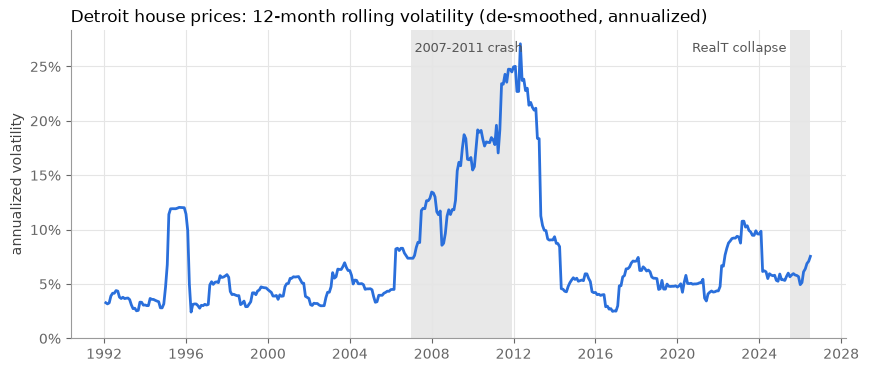

In [ ]:
fig, ax = plt.subplots()
for start, end in [("2007-01", "2011-12"), ("2025-07", "2026-07")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.6, lw=0)
ax.plot(vol.index, vol, color=LINE, lw=2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylim(0, None)
ax.set_title("Detroit house prices: 12-month rolling volatility (de-smoothed, annualized)", loc="left")
ax.set_ylabel("annualized volatility")
ax.text(pd.Timestamp("2007-03"), ax.get_ylim()[1] * 0.93, "2007-2011 crash", color="#555555", fontsize=9)
ax.text(pd.Timestamp("2025-05"), ax.get_ylim()[1] * 0.93, "RealT collapse", color="#555555", fontsize=9, ha="right")
plt.show()

In [ ]:
vol_pct = vol.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
print(pd.DataFrame({"percentile": [f"p{int(q * 100)}" for q in vol_pct.index],
                    "vol": vol_pct.map("{:.1%}".format).values}).to_string(index=False))
print("\nRealT period:")
print(vol.loc["2025-06":].map("{:.1%}".format).to_string())

**Interpretation.**

- **De-smoothing matters.** Correcting for appraisal smoothing (AR(1) ρ = 0.73) raises annualized volatility from 3.6% to 9.1%. The raw index hides most of the risk.
- **The 2007-2011 crash dominates the series,** with a peak of 27%. The peak came in May 2012, about a year after prices bottomed in April 2011: a 12-month rolling window only rises once the large drops are inside it, so the signal lags the price move. For the controller, this means volatility may cut the LTV late in a market shock, which the simulation must test.
- **During the RealT collapse (Jul 2025 to Jul 2026) volatility stayed between 4.9% and 7.5%,** close to the historical median of 5.5%. Detroit prices gave no warning, so a controller driven only by price risk would not have reacted. This supports the operational-collapse side of the hypothesis: the signal has to come from rent and pool liquidity.

### 2.2 Volatility as a fuzzy variable

**Universe:** 0% to 30% annualized volatility (the historical maximum is 27%).
**Terms:** low, medium, high, as trapezoids. The breakpoints are the historical percentiles of the series above, so no
number is chosen by hand:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, p25, p50 | fully low up to p25, no longer low at the median |
| medium | p25, p50, p75, p90 | fully medium between the median and p75 |
| high | p75, p90, 30%, 30% | starts at p75, fully high from p90 |

Adjacent terms cross so that the memberships always sum to 1: every volatility value is covered, with no gaps.

Code: `adaptive_ltv/membership.py` (`volatility_variable`).

In [ ]:
VOL = volatility_variable(vol)

print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in VOL.terms.items()})
cov = VOL.coverage()
print(f"membership sum over the universe: min {cov.min():.3f}, max {cov.max():.3f}")

for label, x in [("median", vol.median()), ("RealT period, max", vol.loc["2025-07":].max()), ("2012 peak", vol.max())]:
    print(f"{label:>18} ({x:.1%}):", {t: round(d, 2) for t, d in VOL.memberships(x).items()})

In [ ]:
realt = vol.loc["2025-07":]
plot_memberships(VOL, "Input 1: volatility, membership functions", "annualized volatility",
                 band=(realt.min(), realt.max()), band_label="RealT period", label_x={"high": 0.24})
plt.show()

**Reading.** The RealT period runs from 4.9% (about half "low", half "medium") to 7.5% (fully "medium"). The 2012 peak is fully
"high". Volatility alone would therefore keep the max LTV near its normal level during the RealT collapse.

### 2.3 Pool utilization

**What it measures.** The share of the pool's stablecoins already lent out: borrowed / (borrowed + idle cash).
At 100% the pool has no idle cash, so lenders cannot withdraw and new loans cannot be funded. Source: DefiLlama,
daily, averaged per month because the controller decides monthly. Code: `adaptive_ltv/inputs.py` (`utilization_signal`).

In [ ]:
util_d = utilization_daily()
util = utilization_signal()

fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(CRUNCH_START), util.index.max(), color=SHADE, alpha=0.6, lw=0)
ax.text(pd.Timestamp("2026-06-01"), 0.52, "crunch", ha="center", color="#555555", fontsize=9)
ax.plot(util.index, util, color=LINE, lw=2)
pct_axis(ax.yaxis)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("utilization (monthly mean)")
ax.set_title("RMM stablecoin utilization", loc="left")
plt.show()

print(util.loc["2025-06":"2026-03"].map("{:.1%}".format).to_string())

**Reading.** Utilization stayed between 84% and 87% for almost two years (one dip to 78% in April 2024), then jumped to 93% in January 2026 and
to 99-100% from February: the pool emptied in two months and never recovered. Utilization therefore moves
*with* the crunch, not before it; it is a coincident signal, not an early warning.

**Fuzzy terms.** The normal range is too narrow (84% to 88%) for percentile-based terms, so the breakpoints follow
observed behaviour:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| healthy | 0, 0, median, 90% | fully healthy up to the pre-crunch median (85.8%) |
| tight | median, 90%, 95%, 99% | 90% is above every month before the crunch (max 87.6%) |
| crunch | 95%, 99%, 100%, 100% | the pool has practically no idle cash |

In [ ]:
UTIL = utilization_variable(util_d)
print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in UTIL.terms.items()})
print(f"membership sum over the universe: min {UTIL.coverage().min():.3f}, max {UTIL.coverage().max():.3f}")
for d in ["2025-12-01", "2026-01-01", "2026-02-01"]:
    print(f"{d[:7]} ({util[d]:.1%}):", {t: round(x, 2) for t, x in UTIL.memberships(util[d]).items()})

plot_memberships(UTIL, "Input 2: pool utilization, membership functions", "utilization",
                 band=(util.loc[:"2025-12"].min(), util.loc[:"2025-12"].max()), band_label="2024-2025",
                 label_x={"healthy": 0.70, "crunch": 0.985}, xlim=(0.6, 1.0))
plt.show()

### 2.4 Rent coverage (stylized)

**What it measures.** The share of the expected rent actually paid to token holders: 100% means rent arrives as
promised, 0% means the property produces no income.

**Why stylized.** RealT's public API went offline after the liquidation and no rent time series is published. The
series is built from documented dates: rent escrow from July 2025, distributions largely halted by the end of
2025, formal suspension in February 2026 (Outlier Media, BridgeDetroit, Lofty). The path between those dates is an
assumption: linear fall from 100% in June 2025 to 20% in December 2025, 10% in January 2026, zero after.
**Limitation:** because the timing of the fall is set by the scenario, the project shows how the controller reacts
to falling rent; it cannot prove that rent fell before the pool emptied. Code: `rent_coverage_stylized`.

In [ ]:
rent = rent_coverage_stylized()

fig, ax = plt.subplots()
ax.plot(rent.index, rent, color=LINE, lw=2, ls="--")
for d, label in [("2025-07-01", "rent escrow"), ("2026-02-01", "suspension")]:
    ax.axvline(pd.Timestamp(d), color="#9a9a9a", lw=1)
    ax.text(pd.Timestamp(d), 1.06, label, ha="center", color="#555555", fontsize=9)
pct_axis(ax.yaxis)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of expected rent paid")
ax.set_title("Rent coverage, stylized from documented dates (dashed = not observed data)", loc="left")
plt.show()

**Fuzzy terms.** With no historical distribution to anchor them, the breakpoints are stated hypotheses:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, 30%, 60% | below 30% the asset is not producing income |
| partial | 30%, 60%, 80%, 95% | a partial payer |
| full | 80%, 95%, 100%, 100% | from 95% rent is paid as expected |

In [ ]:
RENT = rent_variable()
print(f"membership sum over the universe: min {RENT.coverage().min():.3f}, max {RENT.coverage().max():.3f}")
for d in ["2025-08-01", "2025-10-01", "2025-12-01"]:
    print(f"{d[:7]} ({rent[d]:.0%}):", {t: round(x, 2) for t, x in RENT.memberships(rent[d]).items()})

plot_memberships(RENT, "Input 3: rent coverage, membership functions", "share of expected rent paid",
                 label_x={"low": 0.12, "full": 0.975})
plt.show()

### 2.5 Output: max LTV

**What it is.** The largest loan the pool allows per dollar of collateral, set by the controller every month,
between 30% (crisis) and 60% (RealT's fixed value, the benchmark).

**Terms.** Triangles centred on 30% (low), 45% (medium) and 60% (high), each 15 points wide on either side. The
universe runs from 15% to 75% so that, when a single term fires, the centroid lands exactly on its centre: a calm
market gives exactly 60%, the same as the fixed rule, which keeps the comparison fair. The crisp output is then
clipped to [30%, 60%]. Code: `max_ltv_variable`.

In [ ]:
LTV = max_ltv_variable()
fig, ax = plot_memberships(LTV, "Output: max LTV, membership functions", "max LTV")
for x in (LTV_MIN, LTV_MAX):
    ax.axvline(x, color="#9a9a9a", lw=1, ls=":")
plt.show()